# Module 01 — Vectors and Geometry

This notebook is the hands-on companion to the concept guide [README.md](README.md) — read the guide first, or keep it open alongside. Every object is built **from scratch in NumPy** (norms, dot products, projections, Gram–Schmidt, hyperplanes), the hand-worked numbers from the guide are re-computed, and the last section runs the simulations that make high-dimensional geometry believable.

The eight sections mirror the guide: vectors → norms → dot product → cosine similarity → projections → orthonormal bases → hyperplanes → high dimensions.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
plt.rcParams["figure.figsize"] = (7, 4)
np.set_printoptions(precision=4, suppress=True)

## 1. Vectors as arrows, points and data records

A vector $\mathbf{v} \in \mathbb{R}^n$ is an ordered list of $n$ numbers. The same object is an **arrow** (a displacement), a **point** (the arrow's tip) and a **data record** (one row of a dataset). Two operations define everything:

$$\mathbf{u} + \mathbf{v} = (u_1 + v_1, \dots, u_n + v_n), \qquad c\,\mathbf{v} = (c v_1, \dots, c v_n).$$

Below, one and the same `np.array` plays all three roles: first as arrows in the plane, then as a patient record whose year-on-year *change* is a vector subtraction.

u + v  = [4. 1.]
2u     = [2. 4.]
2u - v = [-1.  5.]
change 2024 -> 2025: [  1.   12.  -12.    0.6]   (BP up, cholesterol down)


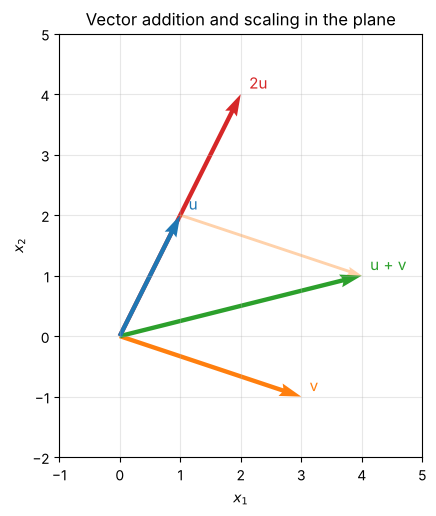

In [2]:
u = np.array([1., 2.])
v = np.array([3., -1.])
print("u + v  =", u + v)
print("2u     =", 2 * u)
print("2u - v =", 2 * u - v)

# the same arithmetic on a data record: one patient visit = (age, systolic BP, cholesterol, BMI)
p_2024 = np.array([54., 130., 210., 27.5])
p_2025 = np.array([55., 142., 198., 28.1])
print("change 2024 -> 2025:", p_2025 - p_2024, "  (BP up, cholesterol down)")

# draw u, v, u + v and 2u as arrows from the origin; the faint arrow shows v placed tip-to-tail after u
fig, ax = plt.subplots(figsize=(5.5, 5.5))
for vec, col, lab in [(2 * u, "C3", "2u"), (v, "C1", "v"), (u + v, "C2", "u + v"), (u, "C0", "u")]:   # u drawn last, on top of 2u
    ax.quiver(0, 0, vec[0], vec[1], angles="xy", scale_units="xy", scale=1, color=col, width=0.012)
    ax.annotate(lab, vec, textcoords="offset points", xytext=(6, 4), color=col, fontsize=11)
ax.quiver(u[0], u[1], v[0], v[1], angles="xy", scale_units="xy", scale=1, color="C1", alpha=0.35, width=0.008)
ax.set_xlim(-1, 5); ax.set_ylim(-2, 5); ax.set_aspect("equal"); ax.grid(alpha=0.3)
ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.set_title("Vector addition and scaling in the plane")
plt.show()

**Notice that** $\mathbf{u} + \mathbf{v}$ is where you land if you walk along $\mathbf{u}$ and then along $\mathbf{v}$ (the faint arrow): tip-to-tail addition and component-wise addition are the same thing. Scaling by 2 keeps the direction and doubles the length.

**Linear independence.** Vectors are independent when no non-trivial combination gives $\mathbf{0}$ — equivalently, when the matrix with those vectors as columns has full rank. Writing a third vector $\mathbf{w}$ in terms of $\mathbf{u}$ and $\mathbf{v}$ means solving two equations in two unknowns. The guide did this by hand for $\mathbf{w} = (5, 0)$ and found $5/7$ and $10/7$.

In [3]:
M = np.column_stack([u, v])                       # 2x2 matrix with u and v as columns
rank = np.linalg.matrix_rank(M)
print("rank of [u v] =", rank, "->", "independent" if rank == 2 else "dependent")

w = np.array([5., 0.])
coeffs = np.linalg.solve(M, w)                    # a*u + b*v = w
print("w = %.4f * u + %.4f * v    (by hand: 5/7 = %.4f, 10/7 = %.4f)" % (coeffs[0], coeffs[1], 5/7, 10/7))
print("check a*u + b*v =", coeffs[0] * u + coeffs[1] * v)

# any three vectors in R^2 are dependent: the rank cannot exceed 2
print("rank of [u v w] =", np.linalg.matrix_rank(np.column_stack([u, v, w])))

rank of [u v] = 2 -> independent
w = 0.7143 * u + 1.4286 * v    (by hand: 5/7 = 0.7143, 10/7 = 1.4286)
check a*u + b*v = [5. 0.]
rank of [u v w] = 2


> **Try it yourself:** replace `v` by `np.array([2., 4.])` (a multiple of `u`) and re-run the two cells above. The rank drops to 1 and `np.linalg.solve` raises `LinAlgError: Singular matrix` — the two arrows lie on one line, so they cannot reach $(5, 0)$.

## 2. Norms and distance

A norm is a ruler. The three you will use constantly:

$$\|\mathbf{x}\|_2 = \sqrt{\sum_i x_i^2}, \qquad \|\mathbf{x}\|_1 = \sum_i |x_i|, \qquad \|\mathbf{x}\|_\infty = \max_i |x_i|,$$

and in general $\|\mathbf{x}\|_p = \big(\sum_i |x_i|^p\big)^{1/p}$. A **unit vector** has norm 1; **normalising** $\mathbf{x}$ means dividing by its norm. The **distance** between two points is the norm of their difference. For $\mathbf{x} = (3, -4, 12)$ the guide found $\|\mathbf{x}\|_2 = 13$, $\|\mathbf{x}\|_1 = 19$ and $\|\mathbf{x}\|_\infty = 12$ — let us compute the $L_2$ norm three ways and confirm the ordering $\|\mathbf{x}\|_\infty \le \|\mathbf{x}\|_2 \le \|\mathbf{x}\|_1 \le \sqrt{n}\,\|\mathbf{x}\|_2$.

In [4]:
x = np.array([3., -4., 12.])

l2_by_hand = np.sqrt(np.sum(x ** 2))     # the definition
l2_dot     = np.sqrt(x @ x)              # via the dot product: ||x||^2 = x . x
l2_numpy   = np.linalg.norm(x)           # the library call
print("L2 three ways      :", l2_by_hand, l2_dot, l2_numpy)

l1, l1_np     = np.sum(np.abs(x)), np.linalg.norm(x, 1)
linf, linf_np = np.max(np.abs(x)), np.linalg.norm(x, np.inf)
print("L1   (ours, numpy) :", l1, l1_np)
print("Linf (ours, numpy) :", linf, linf_np)
print("Linf <= L2 <= L1 <= sqrt(n) L2 :", linf <= l2_dot <= l1 <= np.sqrt(len(x)) * l2_dot,
      "  (sqrt(3) * 13 = %.2f)" % (np.sqrt(3) * 13))

x_hat = x / l2_dot
print("unit vector x_hat  :", x_hat, "  norm:", np.linalg.norm(x_hat))

a, b = np.array([1., 2., 3.]), np.array([4., 6., 3.])
print("distance a <-> b   : L2 = %.3f   L1 = %.3f   Linf = %.3f"
      % (np.linalg.norm(a - b), np.linalg.norm(a - b, 1), np.linalg.norm(a - b, np.inf)))

L2 three ways      : 13.0 13.0 13.0
L1   (ours, numpy) : 19.0 19.0
Linf (ours, numpy) : 12.0 12.0
Linf <= L2 <= L1 <= sqrt(n) L2 : True   (sqrt(3) * 13 = 22.52)
unit vector x_hat  : [ 0.2308 -0.3077  0.9231]   norm: 1.0
distance a <-> b   : L2 = 5.000   L1 = 7.000   Linf = 4.000


The *unit ball* $\{\mathbf{x} : \|\mathbf{x}\|_p \le 1\}$ reveals each norm's personality. We trace its boundary by taking points on the ordinary circle and rescaling each one to have $L_p$ norm exactly 1.

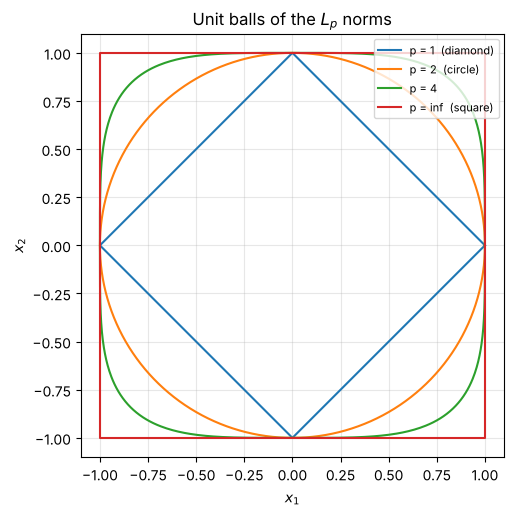

In [5]:
def lp_unit_circle(p, n=721):
    # points on the L2 circle, each rescaled so that its Lp norm equals 1
    t = np.linspace(0, 2 * np.pi, n)
    pts = np.column_stack([np.cos(t), np.sin(t)])
    norms_p = (np.abs(pts) ** p).sum(axis=1) ** (1 / p)
    return pts / norms_p[:, None]

fig, ax = plt.subplots(figsize=(5.5, 5.5))
for p, lab in [(1, "p = 1  (diamond)"), (2, "p = 2  (circle)"), (4, "p = 4")]:
    c = lp_unit_circle(p)
    ax.plot(c[:, 0], c[:, 1], label=lab)
square = np.array([[1, 1], [-1, 1], [-1, -1], [1, -1], [1, 1]], dtype=float)
ax.plot(square[:, 0], square[:, 1], label="p = inf  (square)")
ax.set_aspect("equal"); ax.grid(alpha=0.3); ax.legend(loc="upper right", fontsize=8)
ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.set_title("Unit balls of the $L_p$ norms")
plt.show()

**Notice that** the $L_1$ ball has corners on the coordinate axes — points where one coordinate is exactly zero. When a smooth loss is minimised subject to an $L_1$ constraint, the solution tends to land on such a corner, which is the geometric reason the lasso produces exact zeros (Module 13). The round $L_2$ ball has no corners, so ridge regression only shrinks coefficients. The $L_\infty$ ball is a square: it only cares about the single largest coordinate.

> **Try it yourself:** call `lp_unit_circle(0.5)` and plot it. For $p < 1$ the "ball" is not convex (it caves in towards the origin), which is why $\|\cdot\|_p$ is not a norm for $p < 1$ — the triangle inequality fails.

## 3. The inner (dot) product

$$\mathbf{u}\cdot\mathbf{v} = \sum_i u_i v_i = \|\mathbf{u}\|\,\|\mathbf{v}\|\cos\theta.$$

The algebraic side is a *weighted sum*; the geometric side measures *alignment*. The guide proved the two agree via the law of cosines, $\|\mathbf{u} - \mathbf{v}\|^2 = \|\mathbf{u}\|^2 + \|\mathbf{v}\|^2 - 2\,\mathbf{u}\cdot\mathbf{v}$. We check that identity on a thousand random pairs, together with the two inequalities that follow from it: **Cauchy–Schwarz** $|\mathbf{u}\cdot\mathbf{v}| \le \|\mathbf{u}\|\|\mathbf{v}\|$ and the **triangle inequality** $\|\mathbf{u} + \mathbf{v}\| \le \|\mathbf{u}\| + \|\mathbf{v}\|$.

In [6]:
u, v = np.array([3., 4.]), np.array([4., 3.])
dot = u @ v
cos_theta = dot / (np.linalg.norm(u) * np.linalg.norm(v))
print("u . v = %.1f   cos(theta) = %.3f   theta = %.2f degrees" % (dot, cos_theta, np.degrees(np.arccos(cos_theta))))

# law-of-cosines identity on 1000 random pairs of 5-D vectors (one pair per column)
U = rng.normal(size=(5, 1000)); V = rng.normal(size=(5, 1000))
lhs = np.sum((U - V) ** 2, axis=0)
rhs = np.sum(U ** 2, axis=0) + np.sum(V ** 2, axis=0) - 2 * np.sum(U * V, axis=0)
print("law of cosines: max |lhs - rhs| over 1000 pairs = %.2e" % np.max(np.abs(lhs - rhs)))

dots = np.sum(U * V, axis=0)
nu, nv = np.linalg.norm(U, axis=0), np.linalg.norm(V, axis=0)
print("Cauchy-Schwarz holds for every pair :", bool(np.all(np.abs(dots) <= nu * nv + 1e-12)))
print("triangle inequality holds for every pair:", bool(np.all(np.linalg.norm(U + V, axis=0) <= nu + nv + 1e-12)))
print("largest |u.v| / (||u|| ||v||) observed: %.3f   (equality would need parallel vectors)" % np.max(np.abs(dots) / (nu * nv)))

# orthogonality: rotating (a, b) by 90 degrees gives (-b, a), and the dot product vanishes
perp = np.array([-u[1], u[0]])
print("u =", u, " perp =", perp, " u . perp =", u @ perp)

u . v = 24.0   cos(theta) = 0.960   theta = 16.26 degrees
law of cosines: max |lhs - rhs| over 1000 pairs = 1.07e-14
Cauchy-Schwarz holds for every pair : True
triangle inequality holds for every pair: True
largest |u.v| / (||u|| ||v||) observed: 0.977   (equality would need parallel vectors)
u = [3. 4.]  perp = [-4.  3.]  u . perp = 0.0


**Notice that** the identity holds to floating-point precision ($\sim 10^{-14}$) for every pair, and that the Cauchy–Schwarz ratio never reaches 1 for random vectors — it only equals 1 when one vector is a multiple of the other.

The *weighted-sum* reading is what a linear model computes: features $\mathbf{x}$, weights $\mathbf{w}$, prediction $\mathbf{w}\cdot\mathbf{x} + b$. The *alignment* reading says the same number is large when the feature vector points along $\mathbf{w}$. And a whole dataset is scored with one matrix–vector product `X @ w`: one dot product per row.

In [7]:
x = np.array([54., 130., 210., 27.5])        # one patient: age, systolic BP, cholesterol, BMI
w = np.array([0.04, 0.02, 0.01, 0.05])       # illustrative risk weights per unit of each feature
b = -8.0
score = w @ x + b
theta = np.arccos((w @ x) / (np.linalg.norm(w) * np.linalg.norm(x)))
print("risk score  w.x + b             = %.3f" % score)
print("same number ||w|| ||x|| cos(theta) + b = %.3f   (theta = %.1f degrees)"
      % (np.linalg.norm(w) * np.linalg.norm(x) * np.cos(theta) + b, np.degrees(theta)))

X = np.array([[54., 130., 210., 27.5],
              [40., 118., 180., 22.0],
              [67., 155., 240., 31.2]])
print("scores for three patients, X @ w + b =", X @ w + b)

risk score  w.x + b             = 0.235
same number ||w|| ||x|| cos(theta) + b = 0.235   (theta = 61.5 degrees)
scores for three patients, X @ w + b = [ 0.235 -1.14   1.74 ]


## 4. Cosine similarity and a toy semantic search

$$\cos(\mathbf{u}, \mathbf{v}) = \frac{\mathbf{u}\cdot\mathbf{v}}{\|\mathbf{u}\|\,\|\mathbf{v}\|} \in [-1, 1]$$

is the dot product of the *normalised* vectors, so it ignores length and compares direction only. Here are eight tiny "documents" as bag-of-words count vectors over a ten-word vocabulary. We search them with the query *"model data loss"* twice — once ranking by cosine similarity and once by Euclidean distance — and watch the two rankings disagree exactly where document length differs.

All eight cosine scores come out of **one matrix–vector product**: normalise the rows of the document matrix $D$, normalise the query, and compute $\hat{D}\hat{\mathbf{q}}$. That is what a vector database does, at scale.

In [8]:
vocab = ["model", "data", "train", "loss", "goal", "match", "team", "coach", "price", "market"]
docs = {
    "ML note (short)":          [2, 1, 1, 0, 0, 0, 0, 0, 0, 0],
    "ML article (long)":        [8, 4, 4, 2, 0, 0, 0, 0, 0, 0],
    "Football report":          [0, 0, 0, 0, 3, 2, 2, 1, 0, 0],
    "Football feature (long)":  [0, 0, 1, 0, 6, 5, 6, 2, 0, 0],
    "Market update":            [0, 1, 0, 0, 0, 0, 0, 0, 3, 3],
    "ML for trading":           [2, 2, 0, 0, 0, 0, 0, 0, 2, 2],
    "Sports analytics":         [1, 2, 0, 0, 0, 1, 2, 0, 0, 0],
    "Coach interview":          [0, 0, 2, 0, 0, 0, 2, 3, 0, 0],
}
names = list(docs)
D = np.array([docs[n] for n in names], dtype=float)                 # 8 x 10 document-term matrix
query = np.array([1, 1, 0, 1, 0, 0, 0, 0, 0, 0], dtype=float)       # "model data loss"

def normalize_rows(M):
    n = np.linalg.norm(M, axis=1, keepdims=True)
    return M / np.where(n == 0, 1.0, n)                             # leave all-zero rows alone

cos_scores = normalize_rows(D) @ (query / np.linalg.norm(query))    # all eight cosines at once
euc_dists  = np.linalg.norm(D - query, axis=1)

order_cos, order_euc = np.argsort(-cos_scores), np.argsort(euc_dists)
print(f"{'rank':<6}{'by cosine similarity':<26}{'cos':>6}      {'by Euclidean distance':<26}{'dist':>6}")
print("-" * 80)
for r in range(len(names)):
    i, j = order_cos[r], order_euc[r]
    print(f"{r + 1:<6}{names[i]:<26}{cos_scores[i]:6.3f}      {names[j]:<26}{euc_dists[j]:6.3f}")
print("\nnorm of each document vector:", np.linalg.norm(D, axis=1))

rank  by cosine similarity         cos      by Euclidean distance       dist
--------------------------------------------------------------------------------
1     ML article (long)          0.808      ML note (short)            1.732
2     ML note (short)            0.707      Sports analytics           2.646
3     ML for trading             0.577      ML for trading             3.317
4     Sports analytics           0.548      Market update              4.472
5     Market update              0.132      Coach interview            4.472
6     Football report            0.000      Football report            4.583
7     Football feature (long)    0.000      ML article (long)          8.660
8     Coach interview            0.000      Football feature (long)   10.247

norm of each document vector: [ 2.4495 10.      4.2426 10.0995  4.3589  4.      3.1623  4.1231]


**Notice that** cosine ranks the long ML article at the top — it is the most "about" the query — while Euclidean distance pushes it far down the list, below *Sports analytics* and *ML for trading*, purely because its vector is long ($\|\mathbf{d}\| \approx 10$ versus $\approx 2.4$ for the short note). Euclidean distance mixes "different topic" with "different length"; cosine measures topic only.

The full pairwise picture is the matrix $\hat{D}\hat{D}^\top$ of all document–document cosines.

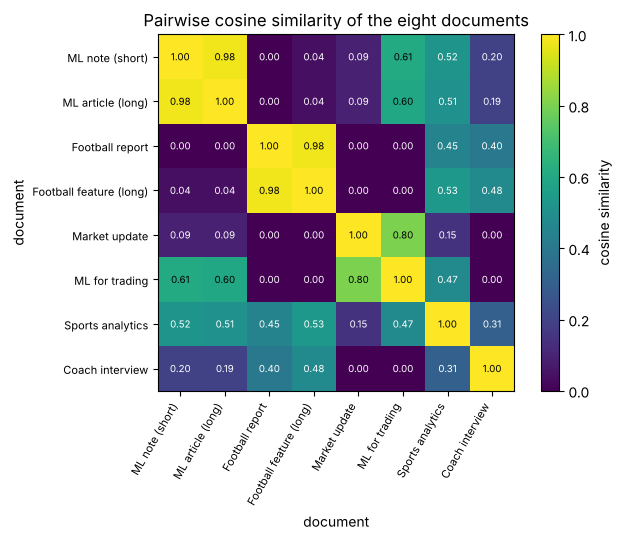

ML note vs ML article: cos = 0.980  (same topic, 4x the length)
ML note vs Football report: cos = 0.000  (no shared words)


In [9]:
Dn = normalize_rows(D)
S = Dn @ Dn.T                                      # 8 x 8 matrix of pairwise cosine similarities

fig, ax = plt.subplots(figsize=(7, 5.5))
im = ax.imshow(S, cmap="viridis", vmin=0, vmax=1)
ax.set_xticks(range(len(names))); ax.set_yticks(range(len(names)))
ax.set_xticklabels(names, rotation=60, ha="right", fontsize=8); ax.set_yticklabels(names, fontsize=8)
for i in range(len(names)):
    for j in range(len(names)):
        ax.text(j, i, f"{S[i, j]:.2f}", ha="center", va="center", fontsize=7, color="w" if S[i, j] < 0.6 else "k")
plt.colorbar(im, ax=ax, label="cosine similarity")
ax.set_title("Pairwise cosine similarity of the eight documents"); ax.set_xlabel("document"); ax.set_ylabel("document")
plt.tight_layout(); plt.show()

print("ML note vs ML article: cos = %.3f  (same topic, 4x the length)" % S[0, 1])
print("ML note vs Football report: cos = %.3f  (no shared words)" % S[0, 2])

> **Try it yourself:** change the query to *"goal team price"* (`[0,0,0,0,1,0,1,0,1,0]`) and re-run the search. Then multiply the query by 10 — which of the two rankings changes, and why?

## 5. Projections

The projection of $\mathbf{a}$ onto the line through $\mathbf{b}$, and the residual left over:

$$\mathbf{p} = \frac{\mathbf{a}\cdot\mathbf{b}}{\mathbf{b}\cdot\mathbf{b}}\,\mathbf{b}, \qquad \mathbf{r} = \mathbf{a} - \mathbf{p}, \qquad \mathbf{r}\cdot\mathbf{b} = 0.$$

$\mathbf{p}$ is the *best approximation* of $\mathbf{a}$ among all multiples $t\mathbf{b}$: the squared error $\|\mathbf{a} - t\mathbf{b}\|^2$ is a parabola in $t$ whose minimum sits at $t^\star = \mathbf{a}\cdot\mathbf{b}/\mathbf{b}\cdot\mathbf{b}$. The guide's example is $\mathbf{a} = (2, 3)$, $\mathbf{b} = (4, 2)$, giving $t^\star = 0.7$, $\mathbf{p} = (2.8, 1.4)$ and $\mathbf{r} = (-0.8, 1.6)$.

t* = 0.700   p = [2.8 1.4]   r = [-0.8  1.6]   r . b = 8.88e-16
Pythagoras: ||p||^2 + ||r||^2 = 13.000   ||a||^2 = 13.000
fraction of ||a||^2 explained by direction b: 0.754  (= cos^2 theta)


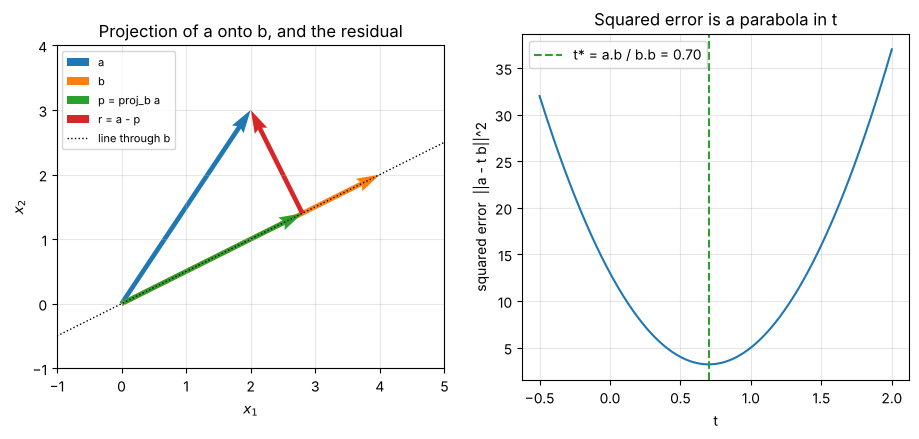

In [10]:
a, b = np.array([2., 3.]), np.array([4., 2.])
t_star = (a @ b) / (b @ b)
p = t_star * b
r = a - p
print("t* = %.3f   p = %s   r = %s   r . b = %.2e" % (t_star, p, r, r @ b))
print("Pythagoras: ||p||^2 + ||r||^2 = %.3f   ||a||^2 = %.3f" % (p @ p + r @ r, a @ a))
print("fraction of ||a||^2 explained by direction b: %.3f  (= cos^2 theta)" % ((p @ p) / (a @ a)))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))
for vec, col, lab in [(a, "C0", "a"), (b, "C1", "b"), (p, "C2", "p = proj_b a")]:
    ax1.quiver(0, 0, vec[0], vec[1], angles="xy", scale_units="xy", scale=1, color=col, width=0.012, label=lab)
ax1.quiver(p[0], p[1], r[0], r[1], angles="xy", scale_units="xy", scale=1, color="C3", width=0.012, label="r = a - p")
ax1.plot([-1, 5], [-0.5, 2.5], "k:", lw=1, label="line through b")
ax1.set_xlim(-1, 5); ax1.set_ylim(-1, 4); ax1.set_aspect("equal"); ax1.grid(alpha=0.3); ax1.legend(fontsize=8, loc="upper left")
ax1.set_xlabel("$x_1$"); ax1.set_ylabel("$x_2$"); ax1.set_title("Projection of a onto b, and the residual")

ts = np.linspace(-0.5, 2.0, 200)
errs = [np.sum((a - t * b) ** 2) for t in ts]
ax2.plot(ts, errs)
ax2.axvline(t_star, color="C2", ls="--", label="t* = a.b / b.b = %.2f" % t_star)
ax2.set_xlabel("t"); ax2.set_ylabel("squared error  ||a - t b||^2"); ax2.set_title("Squared error is a parabola in t")
ax2.legend(); ax2.grid(alpha=0.3)
plt.show()

**Notice that** the residual arrow meets the dotted line at a right angle — $\mathbf{r}\cdot\mathbf{b}$ is zero to machine precision — and that the parabola's minimum is exactly at $t^\star$. Replace the single direction $\mathbf{b}$ by several feature columns and the same picture becomes *least squares*: the fitted values are the projection of the target onto the span of the columns, and the residual vector is orthogonal to every column (Module 02).

## 6. Orthonormal bases and Gram–Schmidt

Vectors $\mathbf{q}_1, \dots, \mathbf{q}_n$ are **orthonormal** when $\mathbf{q}_i\cdot\mathbf{q}_j = 1$ if $i = j$ and $0$ otherwise; as columns of $Q$, this reads $Q^\top Q = I$. Coordinates are then just dot products, and lengths are preserved (Parseval):

$$\mathbf{x} = \sum_i c_i\,\mathbf{q}_i, \qquad c_i = \mathbf{x}\cdot\mathbf{q}_i, \qquad \|\mathbf{x}\|^2 = \sum_i c_i^2 .$$

**Gram–Schmidt** turns any independent set into an orthonormal one: take each new vector, subtract its projections onto the directions already built, normalise. Below is the *modified* variant (each subtraction uses the already-reduced vector, which is numerically a little kinder); `np.linalg.qr` does the same job with Householder reflections, so its columns may differ from ours by a sign.

In [11]:
def gram_schmidt(A):
    # Columns of A (linearly independent) -> Q with orthonormal columns and the same span.
    A = np.asarray(A, dtype=float)
    Q = np.zeros_like(A)
    for j in range(A.shape[1]):
        v = A[:, j].copy()
        for i in range(j):
            v -= (v @ Q[:, i]) * Q[:, i]            # remove the component along q_i
        Q[:, j] = v / np.linalg.norm(v)
    return Q

A = np.column_stack([[1., 1., 0.], [1., 0., 1.], [0., 1., 1.]])      # a1, a2, a3 from the guide
Q = gram_schmidt(A)
print("Q =\n", Q)
print("by hand: q1 = (1,1,0)/sqrt2, q2 = (1,-1,2)/sqrt6, q3 = (-1,1,1)/sqrt3 ->\n",
      np.column_stack([[1, 1, 0] / np.sqrt(2), [1, -1, 2] / np.sqrt(6), [-1, 1, 1] / np.sqrt(3)]))
print("Q^T Q =\n", Q.T @ Q)

Q_qr, R = np.linalg.qr(A)
print("agrees with np.linalg.qr up to column signs:", np.allclose(np.abs(Q), np.abs(Q_qr)))

x = np.array([3., 1., 2.])
c = Q.T @ x                                        # coordinates = dot products with the basis vectors
print("coordinates of x = (3, 1, 2) in the new basis:", c)
print("reconstruction Q c =", Q @ c, "   Parseval: sum c_i^2 = %.3f, ||x||^2 = %.3f" % (c @ c, x @ x))

Q =
 [[ 0.7071  0.4082 -0.5774]
 [ 0.7071 -0.4082  0.5774]
 [ 0.      0.8165  0.5774]]
by hand: q1 = (1,1,0)/sqrt2, q2 = (1,-1,2)/sqrt6, q3 = (-1,1,1)/sqrt3 ->
 [[ 0.7071  0.4082 -0.5774]
 [ 0.7071 -0.4082  0.5774]
 [ 0.      0.8165  0.5774]]
Q^T Q =
 [[ 1.  0.  0.]
 [ 0.  1. -0.]
 [ 0. -0.  1.]]
agrees with np.linalg.qr up to column signs: True
coordinates of x = (3, 1, 2) in the new basis: [ 2.8284  2.4495 -0.    ]
reconstruction Q c = [3. 1. 2.]    Parseval: sum c_i^2 = 14.000, ||x||^2 = 14.000


**Notice that** the third coordinate of $\mathbf{x}$ is zero: $\mathbf{x}$ lies in the plane spanned by $\mathbf{a}_1$ and $\mathbf{a}_2$ (indeed $\mathbf{x} = \mathbf{a}_1 + 2\mathbf{a}_2$), and the orthonormal basis makes that visible at a glance. The same idea organises colour: a pixel's $(R, G, B)$ values re-expressed in a brightness/chroma basis put almost all of their energy into the brightness coordinate — which is why image codecs compress chroma far more aggressively than luma.

In [12]:
pixel = np.array([200., 150., 100.])                       # (R, G, B)
B = np.column_stack([np.ones(3) / np.sqrt(3),              # brightness direction
                     np.array([1., 0., -1.]) / np.sqrt(2),  # red-versus-blue
                     np.array([1., -2., 1.]) / np.sqrt(6)]) # green-versus-magenta
coords = B.T @ pixel
print("B^T B = I :", np.allclose(B.T @ B, np.eye(3)))
print("coordinates (brightness, red-blue, green-magenta):", coords)
print("share of the pixel's energy in the brightness coordinate: %.1f%%" % (100 * coords[0] ** 2 / (pixel @ pixel)))
print("Parseval: %.1f = %.1f" % (coords @ coords, pixel @ pixel))

B^T B = I : True
coordinates (brightness, red-blue, green-magenta): [259.8076  70.7107  -0.    ]
share of the pixel's energy in the brightness coordinate: 93.1%
Parseval: 72500.0 = 72500.0


> **Try it yourself:** feed `gram_schmidt` three *nearly* dependent columns, e.g. `np.column_stack([[1,1,1], [1,1,1+1e-8], [1,1+1e-8,1]])`, and compare `Q.T @ Q` with the result of `np.linalg.qr`. How far from the identity is each? (This is why production code uses QR or SVD rather than textbook Gram–Schmidt.)

## 7. Hyperplanes and half-spaces

The set $\{\mathbf{x} : \mathbf{w}\cdot\mathbf{x} + b = 0\}$ is a hyperplane with **normal vector** $\mathbf{w}$. The **signed distance** of any point to it is

$$\delta(\mathbf{x}) = \frac{\mathbf{w}\cdot\mathbf{x} + b}{\|\mathbf{w}\|},$$

positive on the side $\mathbf{w}$ points to. A linear classifier predicts $\operatorname{sign}(\mathbf{w}\cdot\mathbf{x} + b)$, and the **margin** of a labelled point is $y\,\delta(\mathbf{x})$.

The simplest linear classifier is *nearest centroid*: assign a point to whichever class mean is closer. Working out $\|\mathbf{x} - \boldsymbol{\mu}_1\|^2 < \|\mathbf{x} - \boldsymbol{\mu}_0\|^2$ shows that this is a hyperplane with $\mathbf{w} = \boldsymbol{\mu}_1 - \boldsymbol{\mu}_0$ passing through the midpoint of the two centroids, i.e. $b = -\mathbf{w}\cdot(\boldsymbol{\mu}_0 + \boldsymbol{\mu}_1)/2$.

w = [2.4723 2.1289]   b = -9.622  ||w|| = 3.263
training accuracy: 0.992    misclassified: 1
smallest positive margin: 0.156
rescaling (w, b) by 10 leaves every signed distance unchanged: True


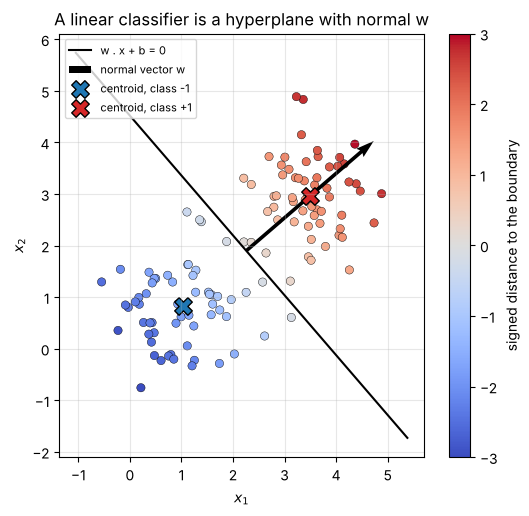

In [13]:
n = 60
X0 = rng.normal(loc=[1.0, 1.0], scale=0.7, size=(n, 2))      # class -1
X1 = rng.normal(loc=[3.5, 3.0], scale=0.7, size=(n, 2))      # class +1
X = np.vstack([X0, X1]); y = np.array([-1] * n + [1] * n)

mu0, mu1 = X0.mean(axis=0), X1.mean(axis=0)
w = mu1 - mu0                                   # normal vector, pointing from class -1 towards class +1
b = -w @ (mu0 + mu1) / 2                        # boundary through the midpoint of the centroids
signed = (X @ w + b) / np.linalg.norm(w)        # signed distances, all points at once
pred = np.where(signed > 0, 1, -1)
margins = y * signed
print("w =", w, "  b = %.3f  ||w|| = %.3f" % (b, np.linalg.norm(w)))
print("training accuracy: %.3f    misclassified: %d" % (np.mean(pred == y), np.sum(margins <= 0)))
print("smallest positive margin: %.3f" % margins[margins > 0].min())
print("rescaling (w, b) by 10 leaves every signed distance unchanged:",
      np.allclose((X @ (10 * w) + 10 * b) / np.linalg.norm(10 * w), signed))

fig, ax = plt.subplots(figsize=(6.5, 5.5))
sc = ax.scatter(X[:, 0], X[:, 1], c=signed, cmap="coolwarm", vmin=-3, vmax=3, edgecolor="k", lw=0.3)
plt.colorbar(sc, ax=ax, label="signed distance to the boundary")
xs = np.linspace(X[:, 0].min() - 0.5, X[:, 0].max() + 0.5, 50)
ax.plot(xs, -(w[0] * xs + b) / w[1], "k-", label="w . x + b = 0")
mid = (mu0 + mu1) / 2
ax.quiver(mid[0], mid[1], w[0], w[1], angles="xy", scale_units="xy", scale=1, color="k", width=0.01, label="normal vector w")
ax.scatter(mu0[0], mu0[1], marker="X", s=160, c="C0", edgecolor="k", label="centroid, class -1")
ax.scatter(mu1[0], mu1[1], marker="X", s=160, c="C3", edgecolor="k", label="centroid, class +1")
ax.set_aspect("equal"); ax.legend(fontsize=8, loc="upper left"); ax.grid(alpha=0.3)
ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.set_title("A linear classifier is a hyperplane with normal w")
plt.show()

**Notice that** $\mathbf{w}$ is *perpendicular* to the decision line, not along it, and that the colour (signed distance) changes only as you move in the direction of $\mathbf{w}$ — moving parallel to the boundary changes nothing. Points near the line have small margins and are the ones a slightly different training set would flip; a support vector machine chooses $\mathbf{w}, b$ to make the smallest margin as large as possible. Scaling $(\mathbf{w}, b)$ changes the raw scores but not the boundary or the distances — which is why logistic regression needs a regulariser to pin down the scale of $\mathbf{w}$.

## 8. High-dimensional geometry

Everything so far holds in any dimension, but the *typical* behaviour of random points changes completely as $d$ grows. For two random vectors with independent standard-normal coordinates,

$$\mathbb{E}[\cos(\mathbf{u}, \mathbf{v})] = 0, \qquad \operatorname{sd}[\cos(\mathbf{u}, \mathbf{v})] = \frac{1}{\sqrt d},$$

so random directions become nearly orthogonal. We draw 300 random vectors for $d = 2, 10, 100, 1000$, compute **all pairwise cosines in one matrix product** $\hat{Z}\hat{Z}^\top$, and compare the spread with $1/\sqrt d$.

     d  std of cosine  1/sqrt(d)  max |cos|
     2         0.7077     0.7071      1.000
    10         0.3150     0.3162      0.955
   100         0.0999     0.1000      0.405
  1000         0.0315     0.0316      0.133


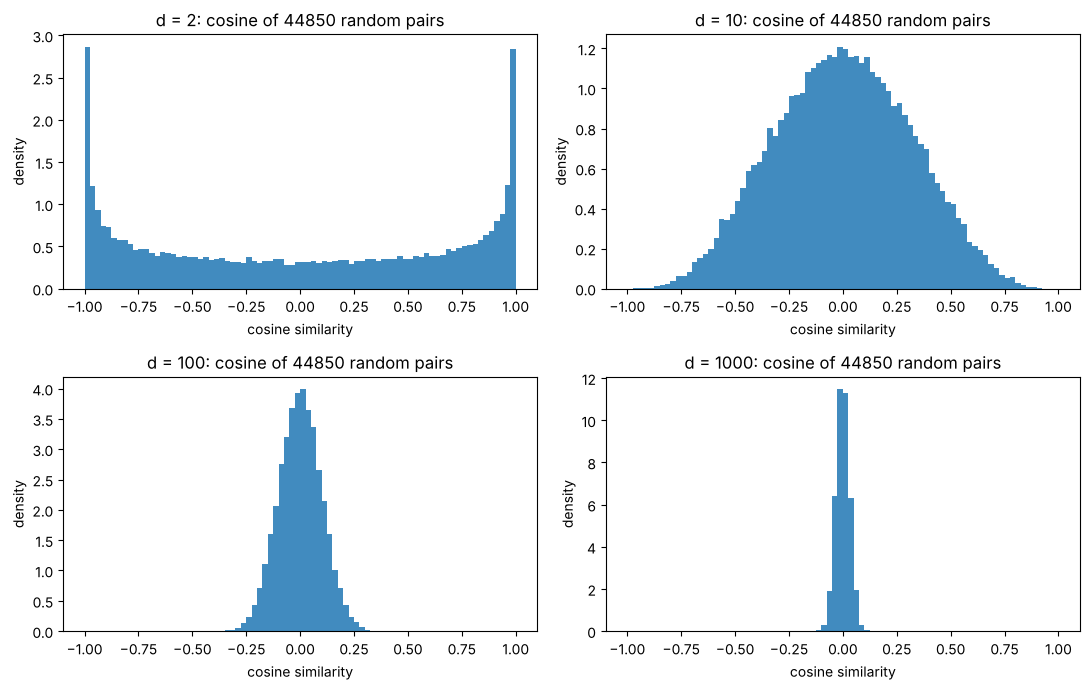

In [14]:
dims, n = [2, 10, 100, 1000], 300
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
print(f"{'d':>6} {'std of cosine':>14} {'1/sqrt(d)':>10} {'max |cos|':>10}")
for ax, d in zip(axes.ravel(), dims):
    Z = rng.normal(size=(n, d))
    Zn = Z / np.linalg.norm(Z, axis=1, keepdims=True)
    C = Zn @ Zn.T                                        # all n x n cosines at once
    cosines = C[np.triu_indices(n, k=1)]                 # each unordered pair exactly once
    print(f"{d:>6} {cosines.std():>14.4f} {1 / np.sqrt(d):>10.4f} {np.abs(cosines).max():>10.3f}")
    ax.hist(cosines, bins=80, range=(-1, 1), density=True, color="C0", alpha=0.85)
    ax.set_title(f"d = {d}: cosine of {n * (n - 1) // 2} random pairs"); ax.set_xlabel("cosine similarity"); ax.set_ylabel("density")
plt.tight_layout(); plt.show()

**Notice that** the measured standard deviation tracks $1/\sqrt d$ almost perfectly, and at $d = 1000$ no pair out of 44,850 reaches a cosine of even $0.15$. (In $d = 2$ the histogram piles up at $\pm 1$: the cosine of a uniformly random angle has an arcsine-shaped density, so in the plane random directions are *more* likely to be nearly parallel than nearly perpendicular — the opposite of high dimensions.) This is the baseline against which any "similarity" must be judged: a cosine of $0.3$ is nothing in 10 dimensions and a ten-sigma event in 1000.

The second surprise is **distance concentration**. For random points in the unit cube, $\|\mathbf{x} - \mathbf{y}\|^2$ is a sum of $d$ independent terms, so its relative spread shrinks like $1/\sqrt d$ — the nearest and the farthest neighbour end up at almost the same distance.

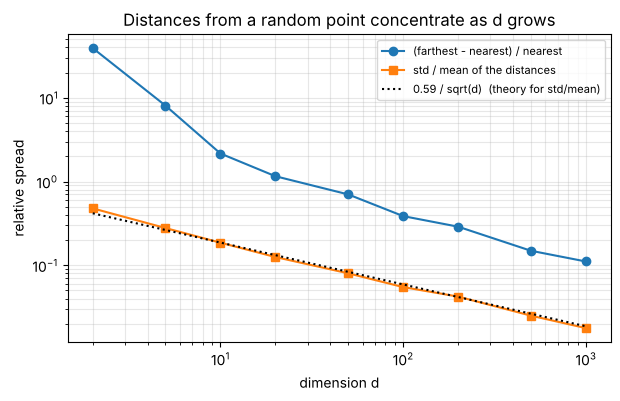

d =     2: farthest neighbour is  3917.7% farther than the nearest;  std/mean = 0.478
d =     5: farthest neighbour is   806.2% farther than the nearest;  std/mean = 0.278
d =    10: farthest neighbour is   215.9% farther than the nearest;  std/mean = 0.186
d =    20: farthest neighbour is   115.6% farther than the nearest;  std/mean = 0.125
d =    50: farthest neighbour is    70.2% farther than the nearest;  std/mean = 0.080
d =   100: farthest neighbour is    38.6% farther than the nearest;  std/mean = 0.055
d =   200: farthest neighbour is    28.9% farther than the nearest;  std/mean = 0.042
d =   500: farthest neighbour is    14.9% farther than the nearest;  std/mean = 0.025
d =  1000: farthest neighbour is    11.1% farther than the nearest;  std/mean = 0.018


In [15]:
dims, n = [2, 5, 10, 20, 50, 100, 200, 500, 1000], 500
contrast, rel_spread = [], []
for d in dims:
    P = rng.random((n, d))                               # uniform in the unit cube
    dist = np.linalg.norm(P[1:] - P[0], axis=1)          # distances from the first point to all others
    contrast.append((dist.max() - dist.min()) / dist.min())
    rel_spread.append(dist.std() / dist.mean())

fig, ax = plt.subplots()
ax.plot(dims, contrast, "o-", label="(farthest - nearest) / nearest")
ax.plot(dims, rel_spread, "s-", label="std / mean of the distances")
ax.plot(dims, 0.59 / np.sqrt(np.array(dims, float)), "k:", label="0.59 / sqrt(d)  (theory for std/mean)")
ax.set_xscale("log"); ax.set_yscale("log"); ax.grid(alpha=0.3, which="both"); ax.legend(fontsize=8)
ax.set_xlabel("dimension d"); ax.set_ylabel("relative spread"); ax.set_title("Distances from a random point concentrate as d grows")
plt.show()
for d, c, s in zip(dims, contrast, rel_spread):
    print(f"d = {d:>5}: farthest neighbour is {100 * c:7.1f}% farther than the nearest;  std/mean = {s:.3f}")

**Notice that** in two dimensions the farthest point is tens of times farther away than the nearest, while at $d = 1000$ the difference is a few percent. A nearest-neighbour method on raw 1000-dimensional noise is essentially picking at random. (The dotted theory line: the relative spread of the *squared* distance is $\approx 1.18/\sqrt d$, and taking the square root halves relative fluctuations, giving $\approx 0.59/\sqrt d$ for the distance itself.)

Third surprise: **volume lives in the corners.** The unit ball has volume $V_d = \pi^{d/2}/\Gamma(d/2 + 1)$, the cube $[-1, 1]^d$ around it has volume $2^d$. We compare the exact ratio with a Monte Carlo estimate.

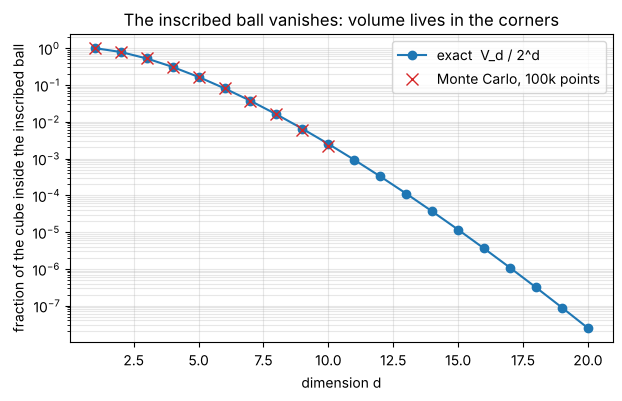

fraction of the cube inside the ball:  d=2: 0.7854   d=3: 0.5236   d=10: 0.00249   d=20: 2.46e-08
fraction of a ball within 90% of its radius, 0.9^d:  d=10: 0.349   d=100: 2.7e-05


In [16]:
from scipy.special import gamma

def ball_volume(d, r=1.0):
    return np.pi ** (d / 2) / gamma(d / 2 + 1) * r ** d

ds = np.arange(1, 21)
ratio = np.array([ball_volume(d) / 2 ** d for d in ds])
mc = []
for d in range(1, 11):                                   # Monte Carlo: fraction of cube points inside the ball
    P = rng.uniform(-1, 1, size=(100_000, d))
    mc.append(np.mean(np.sum(P ** 2, axis=1) <= 1))

fig, ax = plt.subplots()
ax.semilogy(ds, ratio, "o-", label="exact  V_d / 2^d")
ax.semilogy(range(1, 11), mc, "x", ms=9, color="C3", label="Monte Carlo, 100k points")
ax.set_xlabel("dimension d"); ax.set_ylabel("fraction of the cube inside the inscribed ball")
ax.set_title("The inscribed ball vanishes: volume lives in the corners"); ax.legend(); ax.grid(alpha=0.3, which="both")
plt.show()
print("fraction of the cube inside the ball:  d=2: %.4f   d=3: %.4f   d=10: %.5f   d=20: %.2e" % (ratio[1], ratio[2], ratio[9], ratio[19]))
print("fraction of a ball within 90%% of its radius, 0.9^d:  d=10: %.3f   d=100: %.1e" % (0.9 ** 10, 0.9 ** 100))

**Where this bites in deep learning.** Attention scores are dot products $\mathbf{q}\cdot\mathbf{k}$ of $d_k$-dimensional vectors. For roughly unit-variance coordinates that dot product has standard deviation $\sqrt{d_k}$, so without correction the scores for different keys are spread over tens of units and the softmax saturates onto a single key. Dividing by $\sqrt{d_k}$ brings the spread back to one — this is the only reason the $\sqrt{d_k}$ appears in the transformer's attention formula.

In [17]:
d_k, n_keys = 64, 10
K = rng.normal(size=(n_keys, d_k))
Qs = rng.normal(size=(2000, d_k))                         # many queries, to measure the spread of q.k reliably
all_scores = Qs @ K.T                                     # (2000, 10): one dot product per query-key pair
print("std of the raw scores q.k over 20000 pairs: %.2f   (theory: sqrt(d_k) = %.1f)" % (all_scores.std(), np.sqrt(d_k)))
print("std after dividing by sqrt(d_k)           : %.2f" % (all_scores / np.sqrt(d_k)).std())

def softmax(z):
    e = np.exp(z - z.max())
    return e / e.sum()

scores = all_scores[0]                                    # the ten scores of the first query
print("attention weights, raw scores        :", softmax(scores))
print("attention weights, scores / sqrt(d_k):", softmax(scores / np.sqrt(d_k)))
print("largest weight: raw %.3f  vs  scaled %.3f" % (softmax(scores).max(), softmax(scores / np.sqrt(d_k)).max()))

std of the raw scores q.k over 20000 pairs: 8.26   (theory: sqrt(d_k) = 8.0)
std after dividing by sqrt(d_k)           : 1.03
attention weights, raw scores        : [1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
attention weights, scores / sqrt(d_k): [0.4317 0.0444 0.0385 0.0935 0.1064 0.0665 0.0449 0.0256 0.0371 0.1113]
largest weight: raw 1.000  vs  scaled 0.432


> **Try it yourself:** set `d_k = 512` and re-run. The raw-score softmax should become a one-hot vector (all attention on one key, gradients near zero for the rest), while the scaled version stays spread out. Then try dividing by `d_k` instead of `np.sqrt(d_k)` — why is that too much?

## Summary

- A vector is simultaneously an arrow, a point and a data record; addition and scaling are component-wise, and `rank` tells you whether a set of vectors is independent.
- Norms are rulers: $L_2$ (round ball), $L_1$ (diamond — corners give sparsity), $L_\infty$ (square); distances depend on the norm *and* on how features are scaled.
- The dot product is a weighted sum and a measure of alignment at once: $\mathbf{u}\cdot\mathbf{v} = \|\mathbf{u}\|\|\mathbf{v}\|\cos\theta$, verified numerically along with Cauchy–Schwarz and the triangle inequality.
- Cosine similarity compares direction only; it ranked the long ML article first where Euclidean distance buried it. All similarities to a query come from one matrix–vector product.
- Projection $\mathbf{p} = \frac{\mathbf{a}\cdot\mathbf{b}}{\mathbf{b}\cdot\mathbf{b}}\mathbf{b}$ is the best approximation on a line; the residual is orthogonal; the squared error is a parabola.
- Gram–Schmidt builds an orthonormal basis by subtracting projections; coordinates are then dot products and Parseval preserves length; `np.linalg.qr` agrees up to signs.
- A linear classifier is a hyperplane $\mathbf{w}\cdot\mathbf{x} + b = 0$ with normal $\mathbf{w}$; signed distance $(\mathbf{w}\cdot\mathbf{x} + b)/\|\mathbf{w}\|$ is invariant to rescaling $(\mathbf{w}, b)$.
- In high dimension random vectors are nearly orthogonal (cosine spread $1/\sqrt d$), distances concentrate ($\approx 0.59/\sqrt d$ relative spread), and the inscribed ball's share of the cube vanishes — hence $\sqrt{d_k}$ in attention and the failure of $k$-NN on raw high-dimensional inputs.

**Next:** open `exercises.ipynb` and implement these objects yourself — norms without `np.linalg.norm`, top-$k$ cosine retrieval, projections, Gram–Schmidt, signed distances, a distance-concentration experiment, and a small recommender built from user–user cosine similarity. Reference solutions are in `solutions.ipynb`.